# Video Transcript Sentiment Analysis
Multilingual sentiment classification of crisis video transcripts.
One transcript at a time.

## Methodology

### Motivation
After preprocessing, transcript segments need a categorical sentiment label
(POSITIVE / NEGATIVE / NEUTRAL) to quantify the emotional tone of official
messaging during a crisis. These labels complement public sentiment analysis
from YouTube comments.

### Approach
We use `cardiffnlp/twitter-xlm-roberta-base-sentiment` — an XLM-RoBERTa model
fine-tuned on ~200M multilingual tweets. Chosen because:
- **Multilingual**: English, Tagalog, and code-switched text
- **3-class output**: POSITIVE / NEGATIVE / NEUTRAL

### Sentence-Level Aggregation
Long transcript segments may exceed XLM-R's 512-token limit. Workaround:
1. **Split** each segment into sentences via `nltk.sent_tokenize`
2. **Score** every sentence independently
3. **Aggregate** per segment using **most confident sentence** —
   the sentence with the highest confidence score determines the label

*Rationale:* Transcript segments often have one emotionally intense sentence carrying
the signal (grief, apology, blame). Most confident preserves this without
dilution from surrounding filler.

### Pipeline

| Phase | Step | Description |
|---|---|---|
| **1. Load** | Read transcript | Preprocessed CSV with `text`, `sentences`, `source`, `is_shouting` |
| **2. Parse** | Reconstruct sentences | `ast.literal_eval` on stringified `sentences` column |
| **3. Score** | XLM-R inference | Batch loop (`tqdm`, `batch_size=32`, `max_length=512`) |
| **4. Aggregate** | Most confident | Group by segment, pick highest-scoring sentence |
| **5. Analyze** | Shouting analysis, summary statistics, visualizations |

### Cross-Analysis
- *What is the overall sentiment tone of this transcript?*
- *Do ALL-CAPS segments carry more negative sentiment?*
- *Which parts of the speech elicit the strongest emotional language?*

### Input / Output
- **Input:** `transcripts-{name}.csv` from preprocessing
- **Output:** `scored_transcripts-{name}.csv`

## Setup
Import dependencies: `pandas` for data, `transformers.pipeline` for
the model, `matplotlib`/`seaborn` for visualization.

In [1]:
import pandas as pd
import numpy as np
import os
from transformers import pipeline
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import ast
from tqdm import tqdm

plt.rcParams["figure.dpi"] = 150

## Configuration
Transcript selector. Change `TRANSCRIPT_NAME` to switch between
available transcripts (e.g., `ateneo_presscon`, `coach_tab`).

In [12]:
# --- CONFIG ---
BASE_DIR = "../../01-preprocessing/output"
TRANSCRIPT_NAME = "ateneo_presscon"  # or "coach_tab"
BATCH_PATH = os.path.join(BASE_DIR, f"transcripts-{TRANSCRIPT_NAME}.csv")

## Load Batch
Read the preprocessed CSV. Each row is a cleaned transcript segment with
`source`, `start_time`, `end_time`, `text`, `is_shouting`.

In [3]:
batch_df = pd.read_csv(BATCH_PATH)
print(f"Loaded {len(batch_df)} segments from transcripts-{TRANSCRIPT_NAME}.csv")

# Parse the sentences column from stringified list back to Python list
batch_df['sentences'] = batch_df['sentences'].apply(ast.literal_eval)

batch_df.head()

Loaded 50 segments from transcripts-coach_tab.csv


,source,start_time,end_time,text,is_shouting,sentences
0,coach_tab,00:00:00.300,00:00:06.299,"i'm coach tab baldwin, head coach of the atene...",0,"[i'm coach tab baldwin, head coach of the aten..."
1,coach_tab,00:00:06.299,00:00:12.500,i'm here this morning to speak to the families...,0,[i'm here this morning to speak to the familie...
2,coach_tab,00:00:12.500,00:00:17.059,and rene baterbonia.,0,[and rene baterbonia.]
3,coach_tab,00:00:17.059,00:00:25.070,i've been asked to limit my comments this morn...,0,[i've been asked to limit my comments this mor...
4,coach_tab,00:00:25.070,00:00:30.589,in a situation in which i've been utterly lost...,0,[in a situation in which i've been utterly los...


## Exploratory Data Analysis
Summary stats: source, time range, proportion
of all-caps segments, text length distribution.

In [4]:
print(f"Source in transcript: {batch_df['source'].unique()}")
print(f"Time range: {batch_df['start_time'].min()} to {batch_df['end_time'].max()}")
print(f"Shouting segments: {batch_df['is_shouting'].sum()} ({batch_df['is_shouting'].mean():.1%})")
print(f"Text length stats:")
print(batch_df['text'].str.len().describe().to_string())

Source in transcript: <StringArray>
['coach_tab']
Length: 1, dtype: str
Time range: 00:00:00.300 to 00:08:39.649
Shouting segments: 0 (0.0%)
Text length stats:
count    50.000000
mean     74.500000
std      16.284774
min      16.000000
25%      72.000000
50%      78.000000
75%      84.000000
max      95.000000


## Model Loading
Load `cardiffnlp/twitter-xlm-roberta-base-sentiment` via Hugging Face
`pipeline`. Multilingual XLM-RoBERTa fine-tuned for social media
sentiment (positive/negative/neutral).

In [5]:
MODEL_NAME = "cardiffnlp/twitter-xlm-roberta-base-sentiment"

# 1. Initial hardware check
if torch.cuda.is_available():
    device_setting = 0
    print(f"GPU detected: {torch.cuda.get_device_name(0)}. Attempting to initialize...")
else:
    device_setting = -1
    print("No GPU detected. Defaulting to CPU.")

# 2. Try loading on the selected device, fallback to CPU if incompatible
try:
    sentiment_pipeline = pipeline(
        "sentiment-analysis", 
        model=MODEL_NAME, 
        truncation=True,
        device=device_setting
    )
    # Test the pipeline with a dummy string to ensure the GPU kernel actually works
    if device_setting == 0:
        sentiment_pipeline("Sanity check")
    print("Successfully initialized pipeline!")
    
except Exception as e:
    # If a CUDA initialization or kernel error occurs, catch it and force CPU
    print(f"\n[WARNING] GPU initialization failed due to compatibility issues.")
    print(f"Error details: {e}")
    print("Falling back to CPU execution safely...\n")
    
    sentiment_pipeline = pipeline(
        "sentiment-analysis", 
        model=MODEL_NAME, 
        truncation=True,
        device=-1
    )
    print("Successfully initialized pipeline on CPU.")

GPU detected: NVIDIA GeForce GTX 1050 Ti. Attempting to initialize...


/home/mbchavez/Coding/Research/crisis-management-analysis/.venv/lib/python3.11/site-packages/torch/cuda/__init__.py:384: UserWarning: Found GPU0 NVIDIA GeForce GTX 1050 Ti which is of compute capability (CC) 6.1.
The following list shows the CCs this version of PyTorch was built for and the hardware CCs it supports:
- 7.5 which supports hardware CC >=7.5,<8.0
- 8.0 which supports hardware CC >=8.0,<9.0 except {8.7}
- 8.6 which supports hardware CC >=8.6,<9.0 except {8.7}
- 9.0 which supports hardware CC >=9.0,<10.0
- 10.0 which supports hardware CC >=10.0,<11.0 except {10.1}
- 12.0 which supports hardware CC >=12.0,<13.0
Please follow the instructions at https://pytorch.org/get-started/locally/ to install a PyTorch release that supports one of these CUDA versions: 12.6
  _warn_unsupported_code(d, device_cc, code_ccs)
/home/mbchavez/Coding/Research/crisis-management-analysis/.venv/lib/python3.11/site-packages/torch/cuda/__init__.py:502: UserWarning: 
NVIDIA GeForce GTX 1050 Ti with CUDA

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


[WARNING] GPU initialization failed due to compatibility issues.
Error details: CUDA error: no kernel image is available for execution on the device
Search for `cudaErrorNoKernelImageForDevice' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.

Falling back to CPU execution safely...



Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Successfully initialized pipeline on CPU.


## Inference

Each segment is split into sentences (from the `sentences` column).
Sentences are flattened into a single list and scored in batches using
`cardiffnlp/twitter-xlm-roberta-base-sentiment` with explicit
`truncation=True, max_length=512` to avoid the 514-token crash.

**Aggregation**: The sentence with the **highest confidence score** per
segment determines the final label. This captures the dominant emotional
tone — ideal for crisis transcripts where one emotionally intense sentence
(grief, apology, blame) carries the signal.

In [6]:
# Flatten all sentences into one list
all_sentences = [s for sents in batch_df['sentences'] for s in sents]
print(f"Total sentences to score: {len(all_sentences)}")

# Batch inference with tqdm progress
batch_size = 32
all_results = []

for i in tqdm(range(0, len(all_sentences), batch_size), desc="Running XLM-R"):
    batch = all_sentences[i:i+batch_size]
    results = sentiment_pipeline(batch, truncation=True, max_length=512)
    all_results.extend(results)

print("Sentiment analysis complete!")

# Map results back to original segments
sentence_records = []
sent_idx = 0
for idx, row in batch_df.iterrows():
    for sentence in row['sentences']:
        sentence_records.append({
            'comment_idx': idx,
            'sentiment_label': all_results[sent_idx]['label'].upper(),
            'sentiment_score': all_results[sent_idx]['score'],
        })
        sent_idx += 1

df_sentences = pd.DataFrame(sentence_records)

# Per segment: pick the sentence with the highest confidence score
best = df_sentences.loc[df_sentences.groupby('comment_idx')['sentiment_score'].idxmax()].set_index('comment_idx')
batch_df['sentiment_label'] = best['sentiment_label']
batch_df['sentiment_score'] = best['sentiment_score']

batch_df[["text", "sentiment_label", "sentiment_score"]].head(10)


Total sentences to score: 50


Running XLM-R: 100%|██████████| 2/2 [00:02<00:00,  1.18s/it]

Sentiment analysis complete!


,text,sentiment_label,sentiment_score
0,"i'm coach tab baldwin, head coach of the atene...",NEUTRAL,0.769457
1,i'm here this morning to speak to the families...,POSITIVE,0.668303
2,and rene baterbonia.,NEUTRAL,0.461155
3,i've been asked to limit my comments this morn...,NEGATIVE,0.601227
4,in a situation in which i've been utterly lost...,NEGATIVE,0.795369
5,eternity and yet if i had the opportunity to s...,POSITIVE,0.485824
6,"could speak for hours, but they are gone and w...",NEGATIVE,0.601149
7,in being left behind we are carrying immense s...,NEGATIVE,0.760574
8,"carrying immense remorse, but i've known since...",NEGATIVE,0.382703
9,passed away that no matter the magnitude of ou...,NEGATIVE,0.460869


## Shouting Analysis
Compare sentiment distributions between all-caps (shouting)
and normal segments. Tests whether angry expression correlates
with model-detected negative sentiment.

In [7]:
shouting_stats = (
    batch_df.groupby("is_shouting")["sentiment_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
    .rename("percentage")
    .reset_index()
)
shouting_stats

,is_shouting,sentiment_label,percentage
0,0,NEGATIVE,48.0
1,0,POSITIVE,28.0
2,0,NEUTRAL,24.0


In [8]:
shouting_contrast = batch_df.groupby("is_shouting").agg(
    count=("text", "count"),
    mean_confidence=("sentiment_score", "mean"),
    pct_positive=("sentiment_label", lambda x: (x == "POSITIVE").mean() * 100),
    pct_negative=("sentiment_label", lambda x: (x == "NEGATIVE").mean() * 100),
).round(1)
shouting_contrast

,count,mean_confidence,pct_positive,pct_negative
is_shouting,,,,
0,50,0.6,28.0,48.0


## Visualizations
Two plots summarizing the transcript:
1. **Pie chart** — overall transcript sentiment balance
2. **Shouting contrast** — whether all-caps segments are more negative (expected signal of anger/frustration)

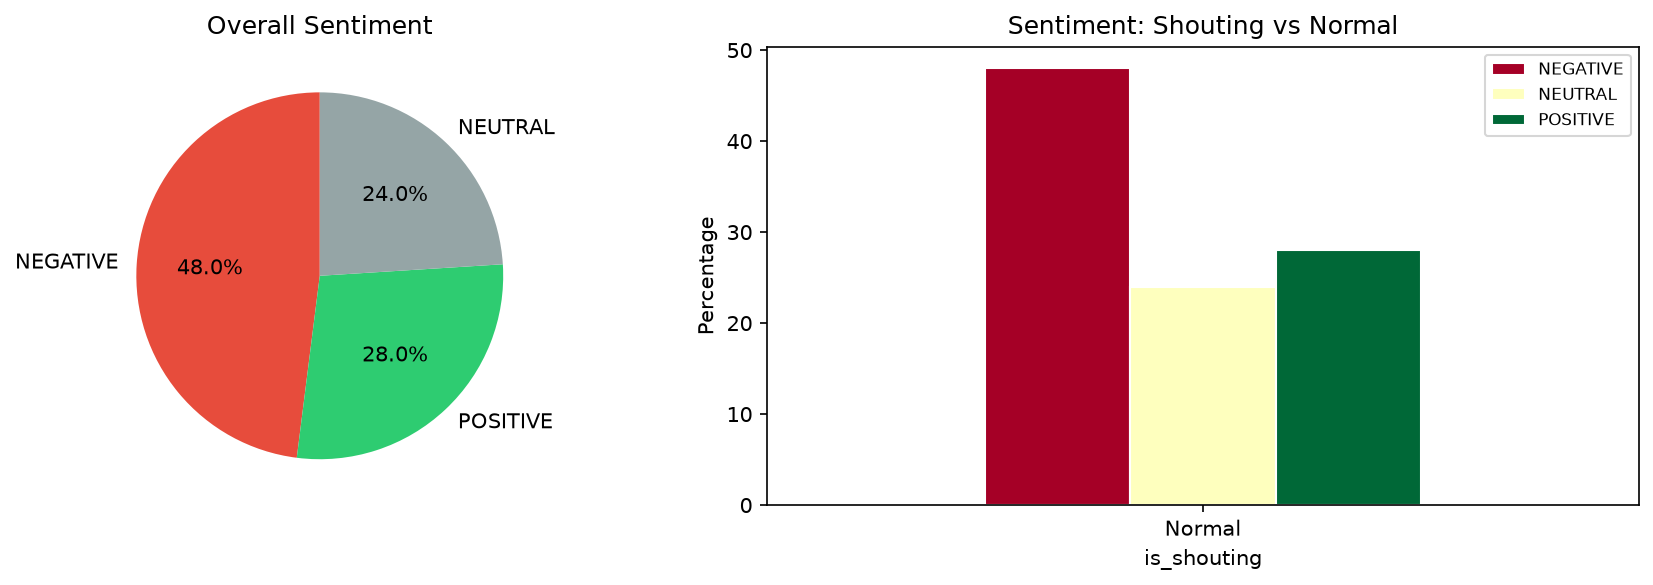

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 1) Overall sentiment pie
overall_counts = batch_df["sentiment_label"].value_counts()
colors = {"POSITIVE": "#2ecc71", "NEGATIVE": "#e74c3c", "NEUTRAL": "#95a5a6"}
axes[0].pie(
    overall_counts.values,
    labels=overall_counts.index,
    autopct="%1.1f%%",
    colors=[colors.get(l, "#999") for l in overall_counts.index],
    startangle=90,
)
axes[0].set_title("Overall Sentiment")

# 2) Shouting vs normal contrast
shouting_plot = batch_df.groupby("is_shouting")["sentiment_label"].value_counts(normalize=True).mul(100).unstack()
shouting_plot.plot(kind="bar", ax=axes[1], colormap="RdYlGn", edgecolor="white")
axes[1].set_title("Sentiment: Shouting vs Normal")
axes[1].set_ylabel("Percentage")
axes[1].set_xticklabels(
    [["Normal", "Shouting"][int(i)] for i in shouting_plot.index],
    rotation=0
)
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

## Export
Save the scored transcript with sentiment labels and confidence scores
for downstream analysis.

In [10]:
output_dir = "../output"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, f"scored_transcripts-{TRANSCRIPT_NAME}.csv")
batch_df.to_csv(output_path, index=False)
print(f"Exported {len(batch_df)} scored segments to {output_path}")

Exported 50 scored segments to ../output/scored_transcripts-coach_tab.csv


### Aggregation Method: Most Confident Sentence

To produce one label per segment from multiple sentences, we compared two strategies:

- **Majority Vote** — assign the most frequent label across sentences
- **Most Confident** — assign the label of the highest-confidence sentence

**Chosen: Most Confident** — transcript segments often have one emotionally intense
sentence (grief, apology, blame) surrounded by filler. The most confident sentence
captures the dominant tone, while majority voting dilutes the signal.

**Note**: May slightly bias NEGATIVE (negative emotions get higher confidence
scores), which is acceptable for detecting crisis distress signals.

In [11]:
# Most confident (already in batch_df)
most_confident = best[['sentiment_label', 'sentiment_score']]
most_confident.columns = ['mc_label', 'mc_score']

# Majority vote for comparison
majority = df_sentences.groupby('comment_idx')['sentiment_label'].agg(
    lambda x: x.mode().iloc[0]
).to_frame('mv_label')

# Compare
comparison = most_confident.join(majority)
comparison['match'] = comparison['mc_label'] == comparison['mv_label']
print(f"Agreement rate between methods: {comparison['match'].mean():.1%}")

disagreements = comparison[~comparison['match']]
print(f"Disagreements: {len(disagreements)} of {len(comparison)} segments")
if len(disagreements) > 0:
    print("\nSample disagreements (Most Confident → Majority):")
    for idx in disagreements.index[:5]:
        row = disagreements.loc[idx]
        print(f"  [{row['mc_label']} ({row['mc_score']:.2f}) vs {row['mv_label']}]")

Agreement rate between methods: 100.0%
Disagreements: 0 of 50 segments
